# Fase 4 — Modelado con ML clásico (características manuales)

**Tarea:** clasificación binaria buena (0) / mala (1) con las 62 características de `fruitq.features`, extraídas de la fruta principal segmentada (`scripts/extract_features.py`). La clase `regular` se agrega después a partir de la probabilidad $P(\text{mala}\mid x)$ (sección 6).

**Modelos**
| Modelo | Por qué se prueba |
|---|---|
| Clase mayoritaria | Piso absoluto: cualquier modelo debe superarlo |
| Regresión logística | **Línea base** lineal e interpretable |
| SVM con kernel RBF | Frontera no lineal y de margen máximo; buena con ~60 dimensiones y ~10⁴ muestras |
| Random Forest | Captura interacciones (p. ej. "oscuro **y** de baja saturación"), es robusto a la escala y da importancias |
| XGBoost | *Boosting*: suele ser el más fuerte con datos tabulares |

**Protocolo**
- Búsqueda de hiperparámetros con `GridSearchCV` y **`StratifiedGroupKFold(k=5)` sobre train**: los grupos de casi duplicados nunca se separan entre pliegues.
- Métrica de selección: **F1-macro**. La validación (`val`) compara modelos; el **test se usa una sola vez**, con el modelo elegido.
- Pesos de muestra $w_i = \dfrac{N}{K\,N_{e(i)}}$, con $e(i)$ el estrato fruta×calidad, para compensar el exceso de granada buena: cada estrato aporta lo mismo a la pérdida.

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import (f1_score, accuracy_score, recall_score, roc_auc_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

from fruitq.config import PROCESSED, FIGURES, MODELS, SEED
from fruitq.features import feature_names

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
MODELS.mkdir(exist_ok=True)
def savefig(name):
    plt.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight"); plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

df = pd.read_parquet(PROCESSED / "features.parquet")
df = df[df.error.fillna("") == ""].reset_index(drop=True)
FEATS = feature_names()
df["y"] = (df.calidad == "mala").astype(int)
tr, va, te = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
Xtr, ytr, gtr = tr[FEATS].values, tr.y.values, tr.grupo.values
Xva, yva, Xte, yte = va[FEATS].values, va.y.values, te[FEATS].values, te.y.values

n_est = tr.estrato.value_counts()
w_tr = (len(tr) / (len(n_est) * tr.estrato.map(n_est))).values
print(f"train {len(tr)} | val {len(va)} | test {len(te)}   (mala en train: {ytr.mean():.1%})")
print(f"Segmentación sin fruta detectada (se usó la imagen completa): {(~df.seg_ok).mean():.1%}")

train 12269 | val 2455 | test 2540   (mala en train: 39.0%)
Segmentación sin fruta detectada (se usó la imagen completa): 0.2%


## 1. Búsqueda de hiperparámetros

In [2]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
pipe = lambda clf: Pipeline([("scaler", StandardScaler()), ("clf", clf)])

busquedas = {
    "Regresión logística": (pipe(LogisticRegression(max_iter=3000)),
                            {"clf__C": [0.01, 0.1, 1, 10]}),
    "SVM (RBF)": (pipe(SVC(kernel="rbf")),
                  {"clf__C": [0.3, 1, 3, 10, 30], "clf__gamma": ["scale", 0.003, 0.01, 0.03]}),
    "Random Forest": (pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1)),
                      {"clf__max_depth": [None, 20, 10], "clf__min_samples_leaf": [1, 3, 10],
                       "clf__max_features": ["sqrt", 0.3]}),
    "XGBoost": (pipe(XGBClassifier(n_estimators=400, subsample=0.8, colsample_bytree=0.8,
                                   random_state=SEED, n_jobs=1, eval_metric="logloss")),
                {"clf__max_depth": [3, 5, 7], "clf__learning_rate": [0.05, 0.1]}),
}

resultados, mejores = [], {}
for nombre, (est, grid) in busquedas.items():
    t0 = time.time()
    gs = GridSearchCV(est, grid, scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True)
    gs.fit(Xtr, ytr, groups=gtr, clf__sample_weight=w_tr)
    mejores[nombre] = gs
    i = gs.best_index_
    resultados.append({
        "modelo": nombre, "mejores hiperparámetros": gs.best_params_,
        "F1 train (CV)": gs.cv_results_["mean_train_score"][i],
        "F1 val (CV)": gs.best_score_, "± std": gs.cv_results_["std_test_score"][i],
        "minutos": (time.time() - t0) / 60,
    })
    print(f"{nombre:<20} F1-CV = {gs.best_score_:.3f}  {gs.best_params_}  ({(time.time()-t0)/60:.1f} min)")
pd.DataFrame(resultados).round(3)

Regresión logística  F1-CV = 0.902  {'clf__C': 10}  (0.2 min)


SVM (RBF)            F1-CV = 0.955  {'clf__C': 10, 'clf__gamma': 'scale'}  (2.2 min)


Random Forest        F1-CV = 0.943  {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1}  (8.3 min)


XGBoost              F1-CV = 0.957  {'clf__learning_rate': 0.1, 'clf__max_depth': 7}  (0.7 min)


,modelo,mejores hiperparámetros,F1 train (CV),F1 val (CV),± std,minutos
0,Regresión logística,{'clf__C': 10},0.913,0.902,0.019,0.212
1,SVM (RBF),"{'clf__C': 10, 'clf__gamma': 'scale'}",0.995,0.955,0.004,2.163
2,Random Forest,"{'clf__max_depth': None, 'clf__max_features': ...",0.999,0.943,0.014,8.300
3,XGBoost,"{'clf__learning_rate': 0.1, 'clf__max_depth': 7}",1.000,0.957,0.010,0.701


**Lectura del sobreajuste.** La diferencia entre "F1 train (CV)" y "F1 val (CV)" estima la **brecha de generalización**. Random Forest y XGBoost profundos suelen llegar a F1 ≈ 1 en train: memorizan. Lo que importa es el F1 de validación y que su desviación entre pliegues sea pequeña.

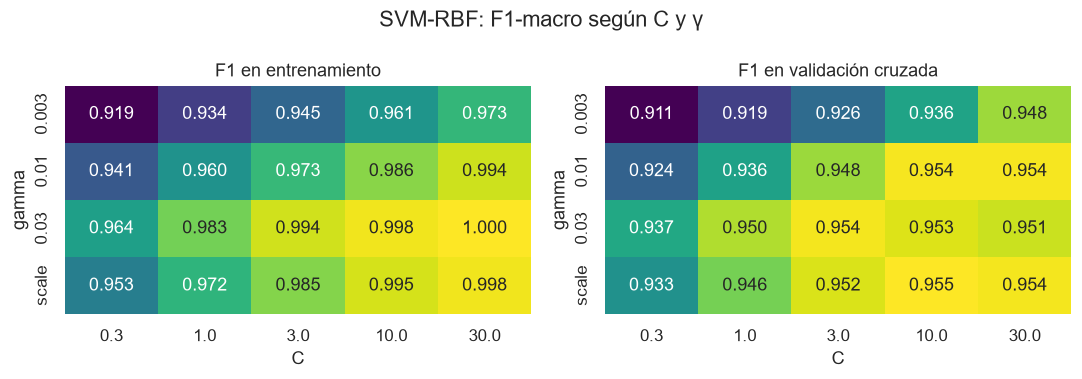

In [3]:
# Efecto de los hiperparámetros de la SVM (evidencia del ajuste para el informe)
r = pd.DataFrame(mejores["SVM (RBF)"].cv_results_)
r["gamma"] = r["param_clf__gamma"].astype(str); r["C"] = r["param_clf__C"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col, titulo in ((axes[0], "mean_train_score", "F1 en entrenamiento"), (axes[1], "mean_test_score", "F1 en validación cruzada")):
    sns.heatmap(r.pivot(index="gamma", columns="C", values=col), annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar=False)
    ax.set_title(titulo)
plt.suptitle("SVM-RBF: F1-macro según C y γ"); plt.tight_layout(); savefig("modelos_svm_grid"); plt.show()

En la SVM, $C$ penaliza los errores de entrenamiento en $\min_{w,b,\xi}\ \tfrac12\|w\|^2 + C\sum_i w_i\,\xi_i$, y $\gamma$ controla el alcance del kernel $K(x,x') = \exp(-\gamma\|x-x'\|^2)$. Con $C$ y $\gamma$ grandes, la frontera se ajusta a cada punto: el F1 de train sube y el de validación baja (**sobreajuste**). Con valores pequeños, la frontera es demasiado suave (**subajuste**).

## 2. Comparación en el conjunto de validación

In [4]:
def scores(model, X):
    if hasattr(model, "predict_proba"):
        try: return model.predict_proba(X)[:, 1]
        except AttributeError: pass
    return model.decision_function(X)

dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
modelos = {"Clase mayoritaria": dummy, **{k: v.best_estimator_ for k, v in mejores.items()}}
filas = []
for nombre, m in modelos.items():
    t0 = time.perf_counter(); p = m.predict(Xva); ms = 1000 * (time.perf_counter() - t0) / len(Xva)
    s = scores(m, Xva) if nombre != "Clase mayoritaria" else np.zeros(len(yva))
    filas.append({"modelo": nombre, "accuracy": accuracy_score(yva, p), "F1-macro": f1_score(yva, p, average="macro"),
                  "recall(mala)": recall_score(yva, p), "AUC": roc_auc_score(yva, s) if s.std() > 0 else 0.5,
                  "ms/imagen": ms})
comp = pd.DataFrame(filas).set_index("modelo").round(3)
comp.to_csv(FIGURES.parent / "tabla_modelos_clasicos_val.csv")
comp

,accuracy,F1-macro,recall(mala),AUC,ms/imagen
modelo,,,,,
Clase mayoritaria,0.610,0.379,0.000,0.500,0.000
Regresión logística,0.917,0.913,0.920,0.964,0.002
SVM (RBF),0.952,0.949,0.911,0.990,0.138
Random Forest,0.944,0.941,0.910,0.982,0.031
XGBoost,0.958,0.956,0.939,0.987,0.007


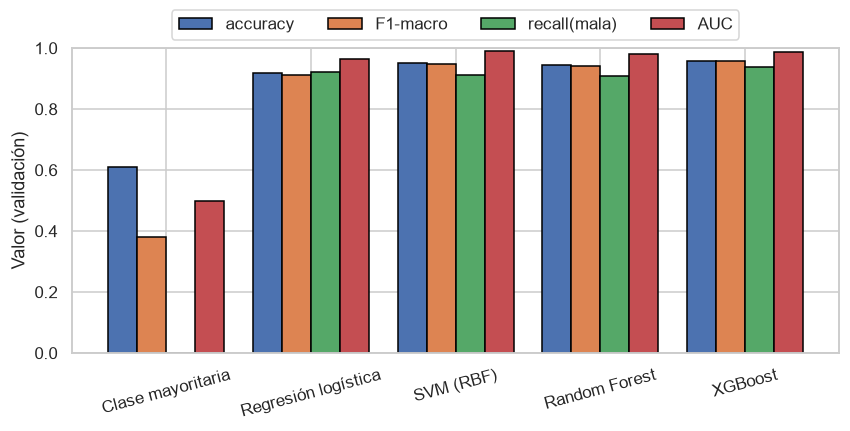

In [5]:
ax = comp[["accuracy", "F1-macro", "recall(mala)", "AUC"]].plot(kind="bar", figsize=(9, 3.6), edgecolor="black", width=0.8)
ax.set_ylim(0, 1); ax.set_ylabel("Valor (validación)"); ax.set_xlabel(""); plt.xticks(rotation=15)
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0)); savefig("modelos_comparacion_val"); plt.show()

## 3. Modelo elegido: evaluación final en test (una sola vez)

Modelo elegido por F1-macro en validación: XGBoost
              precision    recall  f1-score   support

       buena      0.966     0.976     0.971      1492
        mala      0.965     0.950     0.958      1048

    accuracy                          0.965      2540
   macro avg      0.965     0.963     0.964      2540
weighted avg      0.965     0.965     0.965      2540

AUC test: 0.990


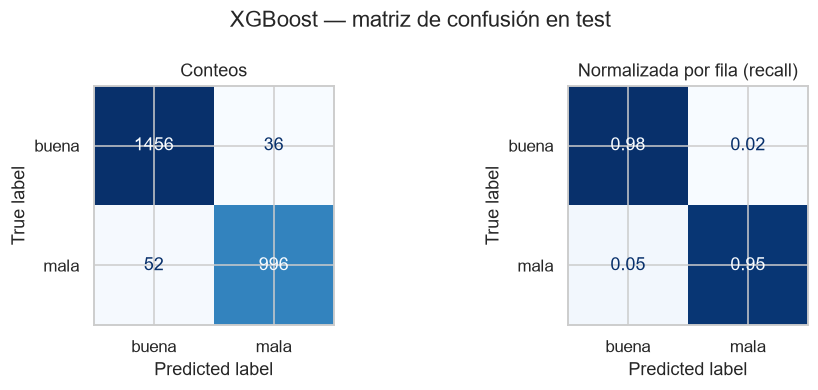

In [6]:
elegido = comp.drop(index="Clase mayoritaria")["F1-macro"].idxmax()
best = modelos[elegido]
print("Modelo elegido por F1-macro en validación:", elegido)
p_te = best.predict(Xte); s_te = scores(best, Xte)
print(classification_report(yte, p_te, target_names=["buena", "mala"], digits=3))
print(f"AUC test: {roc_auc_score(yte, s_te):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, norm, t in ((axes[0], None, "Conteos"), (axes[1], "true", "Normalizada por fila (recall)")):
    ConfusionMatrixDisplay.from_predictions(yte, p_te, display_labels=["buena", "mala"], normalize=norm,
                                            cmap="Blues", ax=ax, colorbar=False, values_format=".2f" if norm else "d")
    ax.set_title(t)
plt.suptitle(f"{elegido} — matriz de confusión en test"); plt.tight_layout(); savefig("modelos_confusion_test"); plt.show()

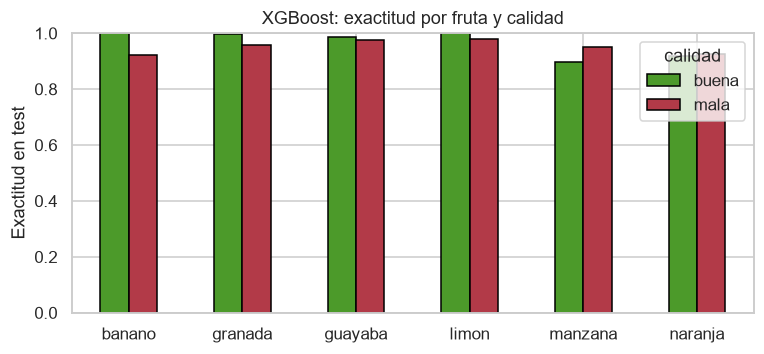

calidad,buena,mala
fruta,,
banano,1.000,0.923
granada,0.996,0.959
guayaba,0.988,0.975
limon,1.000,0.981
manzana,0.896,0.951
naranja,0.919,0.927


In [7]:
te["pred"] = p_te; te["acierto"] = te.pred == te.y
por_fruta = te.groupby(["fruta", "calidad"]).acierto.mean().unstack().round(3)
ax = por_fruta.plot(kind="bar", figsize=(8, 3.3), color={"buena": "#4C9A2A", "mala": "#B23A48"}, edgecolor="black")
ax.set_ylim(0, 1); ax.set_ylabel("Exactitud en test"); ax.set_xlabel(""); plt.xticks(rotation=0)
ax.set_title(f"{elegido}: exactitud por fruta y calidad"); savefig("modelos_por_fruta"); plt.show()
por_fruta

## 4. ¿Qué características usa el modelo?

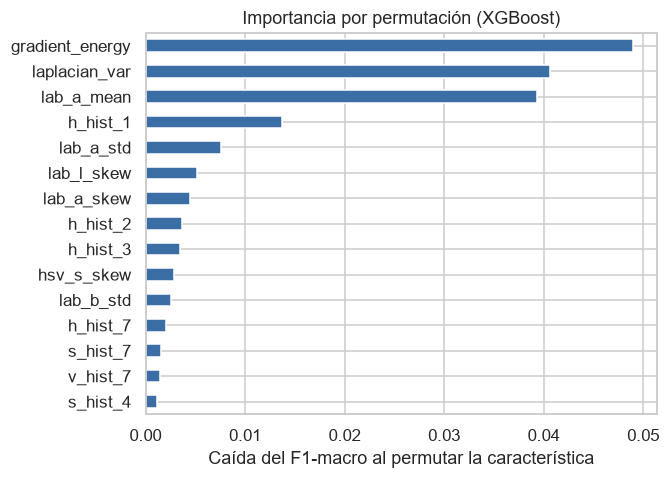

In [8]:
pi = permutation_importance(best, Xva, yva, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False).head(15)
ax = imp[::-1].plot(kind="barh", figsize=(6, 4.5), color="#3B6EA5")
ax.set_xlabel("Caída del F1-macro al permutar la característica"); ax.set_title(f"Importancia por permutación ({elegido})")
savefig("modelos_importancia"); plt.show()

La importancia por permutación mide cuánto empeora el F1 en validación si se baraja una característica, lo que rompe su relación con $y$. Es agnóstica al modelo y, a diferencia de la importancia Gini del RF, no favorece a las variables continuas con muchos valores.

## 5. Galería de errores

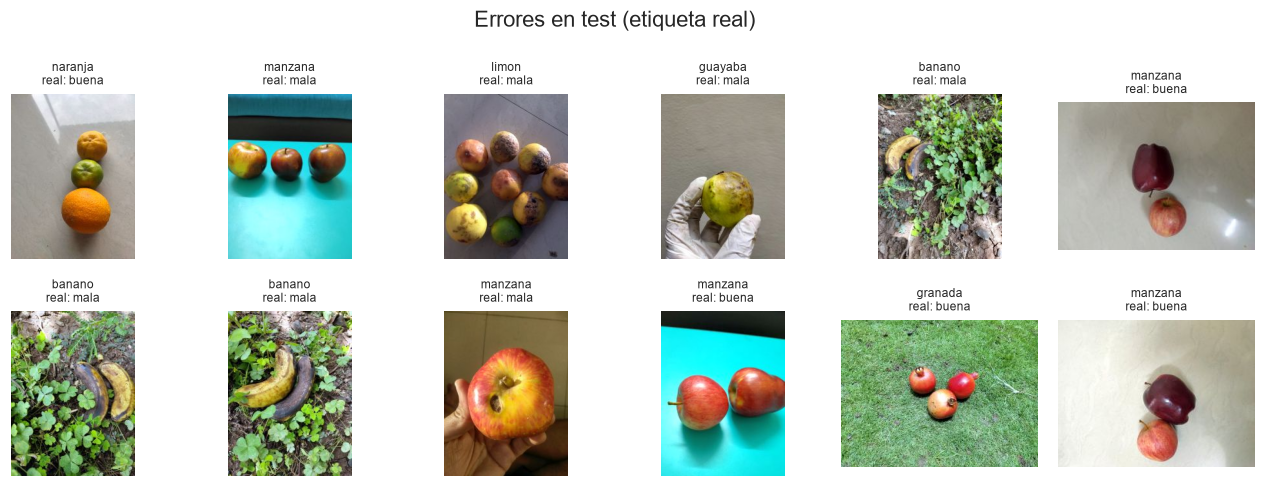

In [9]:
import cv2
from fruitq.io import read_image_max
err = te[~te.acierto].sample(min(12, (~te.acierto).sum()), random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, r in zip(axes.ravel(), err.itertuples()):
    ax.imshow(cv2.cvtColor(read_image_max(r.path, 256), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{r.fruta}\nreal: {r.calidad}", fontsize=8)
plt.suptitle("Errores en test (etiqueta real)"); plt.tight_layout(); savefig("modelos_errores"); plt.show()

## 6. De 2 a 3 clases: umbrales sobre $P(\text{mala}\mid x)$

En vez de entrenar un clasificador de 3 clases sin ejemplos de `regular`, se usa la probabilidad del modelo binario como una **puntuación de deterioro** $s(x) \in [0,1]$:

$$\hat y = \begin{cases}\text{buena} & s(x) < t_1\\ \text{regular} & t_1 \le s(x) < t_2 \\ \text{mala} & s(x) \ge t_2\end{cases}$$

Los umbrales $t_1, t_2$ se ajustan con los recortes etiquetados a mano como `regular`. El histograma muestra cómo se reparte $s(x)$ en test: la zona intermedia es la que ocupará la clase `regular`.

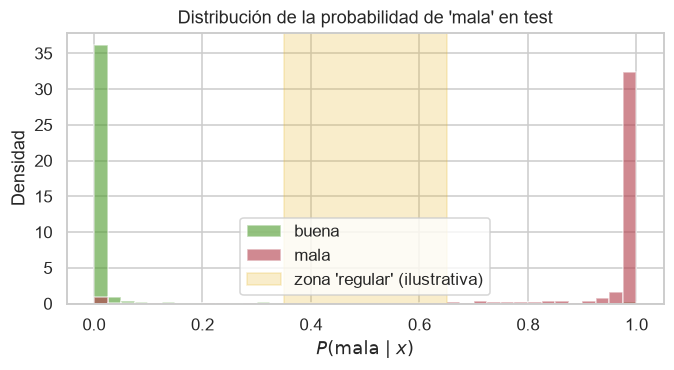

Modelo guardado en models/clasico_mejor.joblib


In [10]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
# La SVM no da probabilidades: se calibra (Platt, sigmoide) sobre validación sin reentrenarla
cal = best if hasattr(best, "predict_proba") else CalibratedClassifierCV(FrozenEstimator(best), method="sigmoid").fit(Xva, yva)
p_mala = cal.predict_proba(Xte)[:, 1]
fig, ax = plt.subplots(figsize=(7, 3.2))
for c, col in (("buena", "#4C9A2A"), ("mala", "#B23A48")):
    ax.hist(p_mala[te.calidad == c], bins=40, alpha=0.6, color=col, label=c, density=True)
ax.axvspan(0.35, 0.65, color="#E8B931", alpha=0.25, label="zona 'regular' (ilustrativa)")
ax.set_xlabel(r"$P(\mathrm{mala} \mid x)$"); ax.set_ylabel("Densidad"); ax.legend()
ax.set_title("Distribución de la probabilidad de 'mala' en test"); savefig("modelos_prob_mala"); plt.show()
joblib.dump({"modelo": cal, "nombre": elegido, "features": FEATS}, MODELS / "clasico_mejor.joblib")
print("Modelo guardado en models/clasico_mejor.joblib")